# Ridge Regression

L2-regularised linear regression: deriving the closed-form solution and tuning lambda.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Machine%20learning/Elements%20of%20Machine%20Learning,%20Linear%20Models%20for%20Classification%20and%20regression%2099/Ridge%20Regression.ipynb)

# **Ridge Regression**

***[Ridge Regression]***

***I Derive the weight update steps of stochastic gradient descent (SGD) for linear regression with L2 regularisation norm or a system of linear equations that uniquely determine the minimum of the regularised error function. this derivation with enough explanation in a markdown cell. The starting point is the definition of the regularised error function and the end result is either the weight update step for this function in (stochastic) gradient descent or a system of linear equations described in matrix/vector notation.***

 Derivation of Weight Update for Stochastic Gradient Descent (SGD) with L2-Regularised Linear Regression

Let us consider the standard linear regression model:
$$
\hat{y} = \mathbf{w}^\top \mathbf{x}
$$

where:
- $$ \mathbf{w} \in \mathbb{R}^d $$ is the weight vector,
- $$ \mathbf{x} \in \mathbb{R}^d $$ is an input sample,
- $$ \hat{y} $$ is the predicted output.

---

#### Objective Function (with L2 Regularisation)

For a single training sample $$ (\mathbf{x}_i, y_i) $$, the L2-regularised loss (Ridge Regression) is defined as:

$$
E(\mathbf{w}) = (y_i - \mathbf{w}^\top \mathbf{x}_i)^2 + \lambda \|\mathbf{w}\|^2
$$

Here:
- The first term is the squared error loss.
- The second term $$ \lambda \|\mathbf{w}\|^2 $$ is the L2 regularisation term (also known as weight decay).
- $$ \lambda \geq 0 $$ is the regularisation strength.

---

#### Step 1: Compute the Gradient

Let $$ \hat{y}_i = \mathbf{w}^\top \mathbf{x}_i $$ and define the error:

$$
e_i = y_i - \hat{y}_i
$$

Now compute the gradient of $$ E(\mathbf{w}) $$ with respect to $$ \mathbf{w} $$:

$$
\nabla_{\mathbf{w}} E = \nabla_{\mathbf{w}} \left[(y_i - \mathbf{w}^\top \mathbf{x}_i)^2\right] + \nabla_{\mathbf{w}} \left[ \lambda \|\mathbf{w}\|^2 \right]
$$

$$
= -2 e_i \mathbf{x}_i + 2\lambda \mathbf{w}
$$

This is the gradient used in stochastic gradient descent.

---

#### Step 2: Weight Update Rule (SGD)

Using a learning rate $$\eta $$, we update the weights in the direction opposite to the gradient:

$$
\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_{\mathbf{w}} E
$$

$$
\Rightarrow \mathbf{w} \leftarrow \mathbf{w} + 2\eta e_i \mathbf{x}_i - 2\eta \lambda \mathbf{w}
$$

Or more cleanly:

$$
\boxed{
\mathbf{w} \leftarrow \mathbf{w} - \eta \left( -2 (y_i - \mathbf{w}^\top \mathbf{x}_i) \mathbf{x}_i + 2\lambda \mathbf{w} \right)
}
$$

---

### Final SGD Update Step:

$$
\boxed{
\mathbf{w} \leftarrow \mathbf{w} - \eta \left[ -2 e_i \mathbf{x}_i + 2\lambda \mathbf{w} \right]
}
$$

This update is applied per training sample in stochastic gradient descent.

---

### Intuition:
- The **first term** $$ -2e_i \mathbf{x}_i $$ adjusts weights to reduce the prediction error.
- The **second term** $$ 2\lambda \mathbf{w} $$ penalises large weights and pulls them toward zero, helping reduce overfitting.


***Using the analytically derived gradient from Step I, implement either a direct or a (stochastic) gradient descent algorithm for Ridge Regression.***

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

In [ ]:

class RidgeSGDRegressor:
    def __init__(self, lr=0.01, lambda_=0.01, n_iters=1000):
        self.lr = lr
        self.lambda_ = lambda_
        self.n_iters = n_iters
        self.w = None

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y).flatten()
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)

        for _ in range(self.n_iters):
            for i in range(n_samples):
                xi = X[i]
                yi = y[i]

                prediction = np.dot(xi, self.w)
                error = yi - prediction

                # Compute gradient for single sample with L2 regularization
                grad = -2 * error * xi + 2 * self.lambda_ * self.w

                # Update weights
                self.w -= self.lr * grad

        return self

    def predict(self, X):
        return np.dot(X, self.w)


***the effect of the L2-regularization on the training and testing errors, using the synthetic data generator i.e., where data is generated according to***
$$
X \sim \text{Uniform}(-0.3, 0.3)
$$

$$
Y = \frac{\cos(3\pi X) + \varepsilon}{2 + 3X}
$$

$$
\varepsilon \sim \mathcal{N}(0, 0.1)
$$


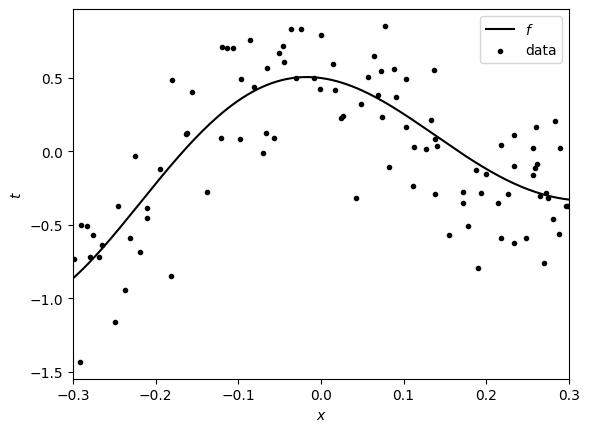

In [ ]:
def f(x):
    return np.cos(3*np.pi*x)/(2+3*x)

def make_additive_noise_data(n, f, a, b, noise=0.1**0.5, random_state=None):
    RNG = np.random.default_rng(random_state)
    x = RNG.uniform(a, b, size=(n, 1))
    y = f(x) + RNG.normal(0, noise, size=(n, 1))
    return x, y

def plot_function(f, a, b, models=[], data=None, ax=None, ax_labels=True, legend=True):
    ax = plt.gca() if ax is None else ax
    xx = np.linspace(a, b, 200).reshape(-1, 1)
    if len(models)==1:
        ax.fill_between(xx.squeeze(), f(xx).squeeze(), models[0].predict(xx).squeeze(), alpha=0.3)
        ax.plot(xx, models[0].predict(xx), label='$y$')
    if len(models) > 1:
        for model in models: ax.plot(xx, model.predict(xx), color='gray', alpha=0.5)
    ax.plot(xx, f(xx), color='black', label='$f$')
    if data is not None:
        x, y = data
        ax.scatter(x, y, marker='.', color='black', label='data')
    if ax_labels:
        ax.set_xlabel('$x$')
        ax.set_ylabel('$t$')
    if legend: ax.legend()
    ax.margins(x=0)

plot_function(f, -0.3, 0.3, data=make_additive_noise_data(100, f, -0.3, 0.3, random_state=0))
plt.show()

In [ ]:
# Generate data
x_train, y_train = make_additive_noise_data(100, f, -0.3, 0.3, random_state=42)
x_train_poly = PolynomialFeatures(degree=5, include_bias=False).fit_transform(x_train)

# Train ridge model
model = RidgeSGDRegressor(lr=0.05, lambda_=0.01, n_iters=200)
model.fit(x_train_poly, y_train)
y_pred = model.predict(x_train_poly)

# Compute MSE
mse = np.mean((y_train.flatten() - y_pred) ** 2)
print("Train MSE:", mse)


Train MSE: 0.21938908742112515


***a Consider the ridge regression model for each λ in {10−10+9i/100, . . . , 10−1 : 0 ≤ i ≤ 100} by creating a pipeline of implemented ridge regressor with a polynomial feature transformer with degree 5.***

***Note:*** ***We can create an array with the above choices for λ via numpy.***
***geomspace(10^-10, 0.1, 101, endpoint=True).***

In [ ]:
# 101 values: λ ∈ {10^(-10 + 9i/100)} for i = 0 to 100
lambdas = np.geomspace(10**-10, 0.1, 101)


***Fit each model at least ten times (resampling a training dataset of size 20 each time) for all choices of λ. To reduce the variance of the experiment make sure that for each repetition all models use the same training dataset (i.e., make the repetitions the outer loop and the choices of λ the inner loop, and sample only one training set per outer loop).***

In [ ]:
# Polynomial transformer
poly = PolynomialFeatures(degree=5, include_bias=False)

# Precompute test set for evaluating generalization error
x_test, y_test = make_additive_noise_data(1000, f, -0.3, 0.3, random_state=0)
x_test_poly = poly.fit_transform(x_test)

repeats = 10
train_mse_matrix = []
test_mse_matrix = []

for repeat in range(repeats):
    # New training set of size 20
    x_train, y_train = make_additive_noise_data(20, f, -0.3, 0.3, random_state=repeat)
    x_train_poly = poly.fit_transform(x_train)

    train_mses = []
    test_mses = []

    for lam in lambdas:
        model = RidgeSGDRegressor(lr=0.05, lambda_=lam, n_iters=500)
        model.fit(x_train_poly, y_train)

        y_train_pred = model.predict(x_train_poly)
        y_test_pred = model.predict(x_test_poly)

        train_mses.append(np.mean((y_train.flatten() - y_train_pred) ** 2))
        test_mses.append(np.mean((y_test.flatten() - y_test_pred) ** 2))

    train_mse_matrix.append(train_mses)
    test_mse_matrix.append(test_mses)

# Convert to numpy arrays for easier analysis
train_mse_matrix = np.array(train_mse_matrix)
test_mse_matrix = np.array(test_mse_matrix)

# Mean MSE over 10 repeats
mean_train_mse = train_mse_matrix.mean(axis=0)
mean_test_mse = test_mse_matrix.mean(axis=0)


***a plot of mean squared errors (different colors for the training and testing errors), where the x-axis is log lambda and y-axis is the log mean squared error. Discuss λ, model complexity, and error rates, corresponding to underfitting and overfitting, by observing your plot.***

***Note: For log-scaling an axis you can use, e.g., pyplot.x scale(’log’). Moreover, note that, as we have a synthetic data source here, we can simply sample a large amount of independent test data and re-use that to approximate the generalisation error for all fits.***


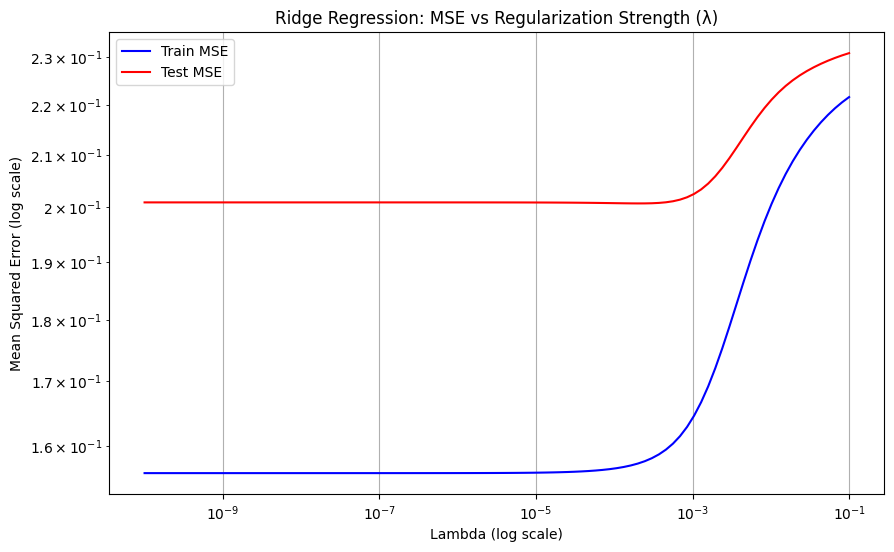

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(lambdas, mean_train_mse, label="Train MSE", color='blue')
plt.plot(lambdas, mean_test_mse, label="Test MSE", color='red')
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Lambda (log scale)")
plt.ylabel("Mean Squared Error (log scale)")
plt.title("Ridge Regression: MSE vs Regularization Strength (λ)")
plt.legend()
plt.grid(True)
plt.show()


Low λ Region (left side, ~10⁻⁹ to 10⁻⁵)
Train MSE is very low → The model fits training data very well.

Test MSE is higher than train MSE → There's a gap, suggesting overfitting.

Model complexity is high: coefficients are large and flexible, capturing noise.

Overfitting Zone
Model memorizes training data and performs poorly on unseen data.

High λ Region (right side, ~10⁻³ to 10⁻¹)
Both train and test MSE increase.

Train MSE rises steeply → Model cannot even fit training data.

Test MSE also increases → Model is too simple, underfits real trends.

Underfitting Zone
Model is too rigid and cannot learn the underlying pattern.

Middle λ Region (~10⁻⁵ to 10⁻³)
Test MSE is lowest here.

Train and test curves are close, with minimal gap.

Good balance between fitting and generalization.

Best Generalization Zone
This is the optimal region where λ controls complexity just right.

